# 02 · Exploratory Analysis

**Plain English:** how much does the business sell, when, where, and what?

**Technical:** every number comes from SQL queries in `src.analytics.eda` against the SQLite
`transactions` table, so the dashboard and this notebook share one source of truth.

In [1]:
import sys; sys.path.insert(0, "..")
import plotly.io as pio
pio.renderers.default = "png"  # static images so charts render on GitHub
import kaleido; kaleido.start_sync_server(silence_warnings=True)  # one shared browser for reliable PNG export
import logging, warnings
logging.getLogger("kaleido").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="The kopts argument")

import pandas as pd
import plotly.express as px
from src.analytics import eda
from src.data.database import query
from src.config import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Headline KPIs

In [2]:
k = eda.kpis()
start, end = eda.date_range()
print(f"Period: {start} to {end}")
pd.Series({
    "Revenue (USD)": f"{k['revenue']:,.0f}",
    "Orders": f"{k['orders']:,}",
    "Customers": f"{k['customers']:,}",
    "Units sold": f"{k['units']:,}",
    "Avg order value (USD)": f"{k['avg_order_value']:,.2f}",
})

Period: 2009-12-01 to 2011-12-09


Revenue (USD)            26,022,173
Orders                       36,332
Customers                     5,839
Units sold               10,099,157
Avg order value (USD)        716.23
dtype: str

## 2. A raw SQL example
The analytics layer is plain, parameterised SQL. Here is one query run directly:
revenue per year.

In [3]:
query("""
    SELECT SUBSTR(invoice_date, 1, 4) AS year,
           ROUND(SUM(revenue), 0)     AS revenue,
           COUNT(DISTINCT invoice)    AS orders
    FROM transactions
    WHERE invoice_date >= ?
    GROUP BY year ORDER BY year""", ("2009-12-01 00:00:00",))

,year,revenue,orders
0,2009,1059999.0,1491
1,2010,12705456.0,17949
2,2011,12256717.0,16892


## 3. Monthly revenue trend
Watch for seasonality: a gift wholesaler should peak before Christmas.
(December 2011 is a partial month: data ends on the 9th.)

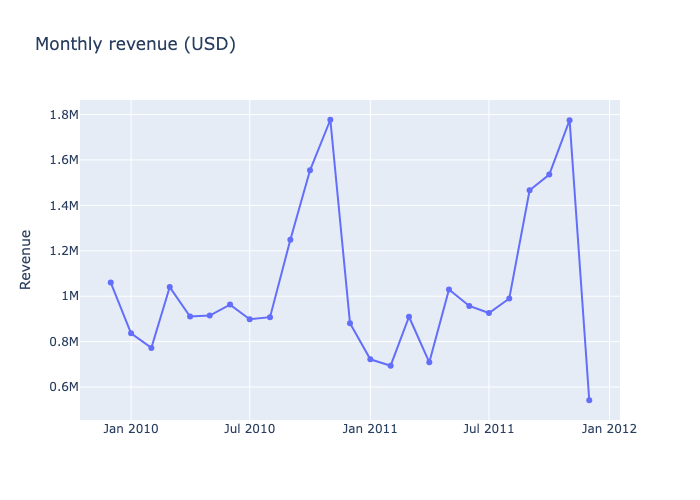

Peak month: 2010-11 with USD 1,777,177


In [4]:
monthly = eda.monthly_revenue()
fig = px.line(monthly, x="month", y="revenue", markers=True,
              title="Monthly revenue (USD)", labels={"revenue": "Revenue", "month": ""})
fig.write_image(FIGURES_DIR / "monthly_revenue.png", width=1000, height=450)
fig.show()
peak = monthly.loc[monthly["revenue"].idxmax()]
print(f"Peak month: {peak['month']} with USD {peak['revenue']:,.0f}")

## 4. Revenue by country

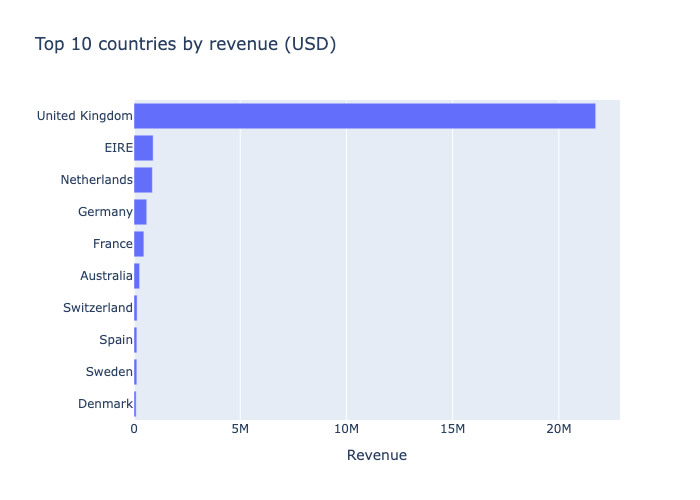

United Kingdom accounts for 83.5% of revenue.


In [5]:
by_country = eda.revenue_by_country(top_n=10)
fig = px.bar(by_country.iloc[::-1], x="revenue", y="country", orientation="h",
             title="Top 10 countries by revenue (USD)", labels={"revenue": "Revenue", "country": ""})
fig.write_image(FIGURES_DIR / "revenue_by_country.png", width=1000, height=450)
fig.show()
uk_share = by_country.iloc[0]["revenue"] / k["revenue"]
print(f"{by_country.iloc[0]['country']} accounts for {uk_share:.1%} of revenue.")

## 5. Top products

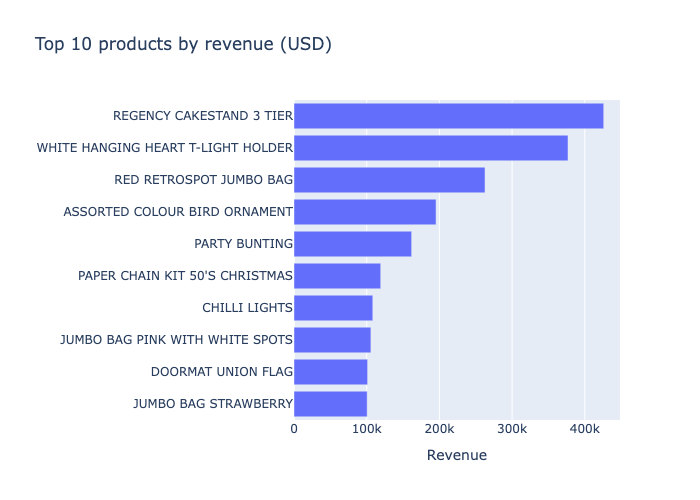

,stock_code,description,revenue,units,orders
0,22423,REGENCY CAKESTAND 3 TIER,426053.85,23428,3207
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,376940.18,88453,4864
2,85099B,RED RETROSPOT JUMBO BAG,262796.96,92538,3244
3,84879,ASSORTED COLOUR BIRD ORNAMENT,195411.37,77784,2645
4,47566,PARTY BUNTING,161831.13,23262,2066
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,119297.24,27955,1680
6,79321,CHILLI LIGHTS,108423.42,14737,916
7,22386,JUMBO BAG PINK WITH WHITE SPOTS,105796.43,36886,1759
8,48138,DOORMAT UNION FLAG,101274.57,9857,1502
9,85099F,JUMBO BAG STRAWBERRY,100666.02,35609,1509


In [6]:
products = eda.top_products(top_n=10)
fig = px.bar(products.iloc[::-1], x="revenue", y="description", orientation="h",
             title="Top 10 products by revenue (USD)", labels={"revenue": "Revenue", "description": ""})
fig.show()
products[["stock_code", "description", "revenue", "units", "orders"]]

**Data-quality note:** bulk orders that were cancelled minutes later (e.g. 80,995 units of a single product) used to appear here as top sellers. The `cancelled_sales` cleaning rule now removes any sale reversed by a matching cancellation, so this list reflects real demand.

## 6. When do customers buy? (weekday x hour)
Weekday 0 = Sunday. Blank cells mean no sales at that hour. Saturday is almost empty (share printed below).

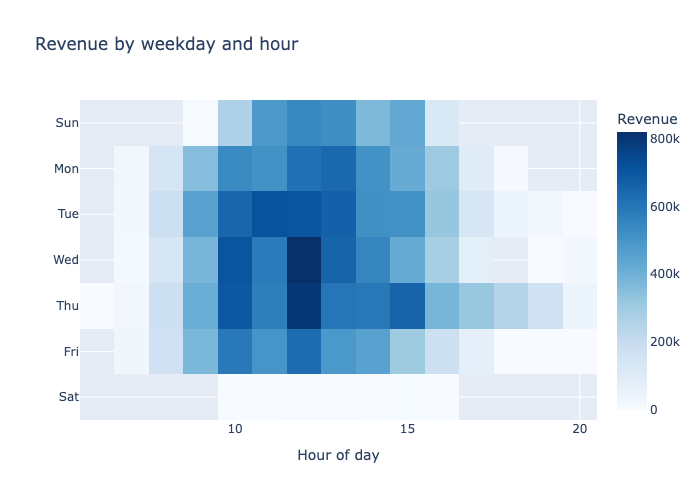

Busiest slot: Wed 12:00
Saturday share of revenue: 0.06%


In [7]:
DAYS = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
heat = (eda.weekday_hour_revenue()
        .pivot(index="weekday", columns="hour", values="revenue")
        .rename(index=dict(enumerate(DAYS))))
fig = px.imshow(heat, aspect="auto", color_continuous_scale="Blues",
                labels={"color": "Revenue", "x": "Hour of day", "y": ""},
                title="Revenue by weekday and hour")
fig.show()
busiest = eda.weekday_hour_revenue().nlargest(1, "revenue").iloc[0]
print(f"Busiest slot: {DAYS[int(busiest['weekday'])]} {int(busiest['hour'])}:00")
day_share = heat.sum(axis=1) / heat.sum().sum()
print(f"Saturday share of revenue: {day_share['Sat']:.2%}")

## 7. How many orders does each customer place?
This shows how much of the customer base comes back, which motivates the RFM and prediction work.

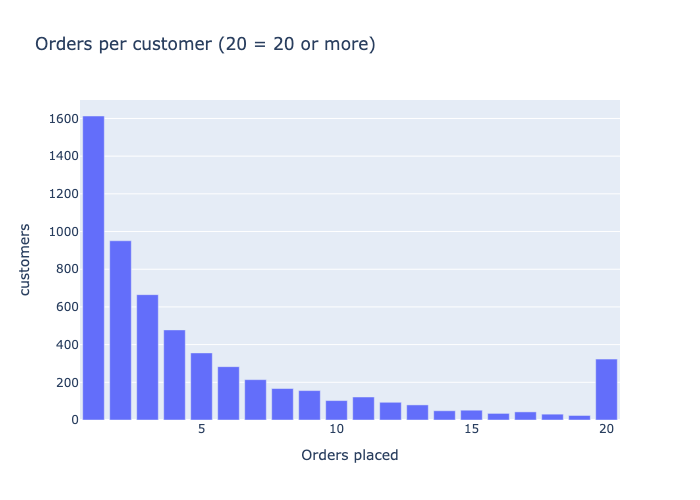

27.6% of customers ordered only once; median orders per customer: 3


In [8]:
opc = eda.orders_per_customer()
capped = opc.assign(orders=opc["orders"].clip(upper=20)).groupby("orders", as_index=False)["customers"].sum()
fig = px.bar(capped, x="orders", y="customers",
             title="Orders per customer (20 = 20 or more)", labels={"orders": "Orders placed"})
fig.show()
one_timers = opc.loc[opc["orders"] == 1, "customers"].sum() / opc["customers"].sum()
print(f"{one_timers:.1%} of customers ordered only once; median orders per customer: "
      f"{opc.loc[opc['customers'].cumsum() >= opc['customers'].sum() / 2, 'orders'].iloc[0]}")